<a href="https://colab.research.google.com/github/Ankurchatterjee-me/DataScienceProject/blob/main/AIOps_KaggleSupported_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Load CSV: Colab upload first, then local fallbacks. No Kaggle API credentials required.
from pathlib import Path
import hashlib, sys

DATA_PATH = None

# Colab upload (only runs inside Google Colab)
try:
    from google.colab import files  # type: ignore
    print('Colab detected — please upload your Kaggle CSV when the file picker appears.')
    uploaded = files.upload()
    if uploaded:
        name = next(iter(uploaded))
        DATA_PATH = Path('/content') / name
        print('Uploaded to', DATA_PATH)
except ImportError:
    print('Not in Colab — using local path search.')

CANDIDATES = [
    DATA_PATH,
    Path('/content/processed_events_analysis.csv'),
    Path('/content/user-uploaded-kaggle.csv'),
    Path('data/user-uploaded-kaggle.csv'),
    Path('../data/user-uploaded-kaggle.csv'),
    Path('processed_events_analysis.csv'),
    Path('data/kaggle_aiops_logs/processed_events_analysis.csv'),
]
for p in CANDIDATES:
    if p is not None and Path(p).is_file():
        DATA_PATH = Path(p).resolve()
        break

if DATA_PATH is None or not DATA_PATH.is_file():
    raise FileNotFoundError(
        'CSV not found. In Colab: upload processed_events_analysis.csv. '
        'Locally: place it at data/user-uploaded-kaggle.csv'
    )

raw = DATA_PATH.read_bytes()
sha = hashlib.sha256(raw).hexdigest()
print('DATA_PATH:', DATA_PATH)
print('bytes:', len(raw))
print('sha256:', sha)
print('Python:', sys.version.split()[0])


Colab detected — please upload your Kaggle CSV when the file picker appears.


Saving processed_events_analysis.csv to processed_events_analysis.csv
Uploaded to /content/processed_events_analysis.csv
DATA_PATH: /content/processed_events_analysis.csv
bytes: 546099
sha256: 58e0de715ab92772ce37333641f3b14472befe06108a5cf5dbf5617a04aa78fc
Python: 3.13.18


In [3]:
import json
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.ensemble import IsolationForest

print('Library versions (record these for repeatability):')
print('  pandas', pd.__version__)
print('  matplotlib', matplotlib.__version__)
print('  seaborn', sns.__version__)
print('  scikit-learn', sklearn.__version__)

df = pd.read_csv(DATA_PATH)
print('\nshape:', df.shape)
print('columns:', list(df.columns))

# Coerce duration honestly: non-numeric -> NaN (missing), keep zeros
df['duration_ms'] = pd.to_numeric(df['duration_ms'], errors='coerce')

n = len(df)
n_miss = int(df['duration_ms'].isna().sum())
n_zero = int((df['duration_ms'] == 0).sum())
n_pos = int((df['duration_ms'] > 0).sum())
print('\nduration_ms: missing', n_miss, f'({100*n_miss/n:.2f}%)')
print('duration_ms: zero', n_zero)
print('duration_ms: >0', n_pos)
print('duration_ms: non-missing total', n - n_miss)

print('\nstatus counts:')
print(df['status'].value_counts(dropna=False))
print('\nevent_type counts:')
print(df['event_type'].value_counts(dropna=False))

# UTC timestamps (dataset-native offsets are +00:00)
df['timestamp_utc'] = pd.to_datetime(df['timestamp'], utc=True, errors='coerce')
print('\ntimestamp_utc min/max:', df['timestamp_utc'].min(), '→', df['timestamp_utc'].max())
print('Note: charts are labeled UTC because the file stores +00:00 — not a personal schedule.')


Library versions (record these for repeatability):
  pandas 2.2.3
  matplotlib 3.10.0
  seaborn 0.13.2
  scikit-learn 1.6.1

shape: (1746, 35)
columns: ['received_at', 'environment', 'project', 'event_count', 'schema_version', 'sdk_version', 'event_type', 'category', 'severity', 'status', 'timestamp', 'hostname', 'os', 'os_version', 'python_version', 'region', 'app_version', 'instance_id', 'process_id', 'trace_id', 'message', 'file', 'line', 'logger_name', 'level', 'method', 'path', 'status_code', 'duration_ms', 'hour', 'date', 'day_of_week', 'month', 'week', 'day']

duration_ms: missing 1202 (68.84%)
duration_ms: zero 19
duration_ms: >0 525
duration_ms: non-missing total 544

status counts:
status
SUCCESS    1275
FAILURE     471
Name: count, dtype: int64

event_type counts:
event_type
DB_QUERY            717
INCOMING_REQUEST    544
SERVER_ERROR        194
ROUTING_ERROR       110
LOG                  69
HTTP_EXCEPTION       50
DB_ERROR             33
HTTP_ERROR           17
HTTP_CALL  

In [4]:
# Duration-only analytical subset (exclude missing; keep zeros)
sub = df.dropna(subset=['duration_ms']).copy()
print('subset rows (non-missing duration_ms):', len(sub))
print('event_type in subset:\n', sub['event_type'].value_counts())
print('zeros retained in subset:', int((sub['duration_ms'] == 0).sum()))

sub['sev_code'] = sub['severity'].map({'LOW': 0, 'MEDIUM': 1, 'HIGH': 2}).fillna(1).astype(float)
sub['fail'] = (sub['status'] == 'FAILURE').astype(float)
# hour from UTC timestamp when available, else file column
if 'hour' in sub.columns:
    sub['hour_feat'] = pd.to_numeric(sub['hour'], errors='coerce')
else:
    sub['hour_feat'] = sub['timestamp_utc'].dt.hour
sub['hour_feat'] = sub['hour_feat'].fillna(0).astype(float)

X = sub[['duration_ms', 'sev_code', 'fail', 'hour_feat']].astype(float)
clf = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42,
)
sub['anomaly_flag'] = clf.fit_predict(X)  # -1 anomalous, 1 normal
n_flags = int((sub['anomaly_flag'] == -1).sum())
n_sub = len(sub)
print('\nIsolationForest flags:', n_flags, '/', n_sub,
      f'({100 * n_flags / n_sub:.2f}%)')
print('contamination hyperparameter: 0.05 (instructed rate ≈5%, not discovered prevalence)')

METRICS = {
    'csv_path': str(DATA_PATH),
    'sha256': sha,
    'bytes': len(raw),
    'n_rows': int(n),
    'n_cols': int(df.shape[1]),
    'status_counts': {str(k): int(v) for k, v in df['status'].value_counts(dropna=False).items()},
    'event_type_counts': {str(k): int(v) for k, v in df['event_type'].value_counts(dropna=False).items()},
    'duration_missing': n_miss,
    'duration_zero': n_zero,
    'duration_positive': n_pos,
    'iforest_n': n_sub,
    'iforest_flags': n_flags,
    'iforest_rate_pct': round(100 * n_flags / n_sub, 2),
    'contamination': 0.05,
    'n_estimators': 100,
    'random_state': 42,
    'features': ['duration_ms', 'sev_code', 'fail', 'hour_feat'],
    'timezone_label': 'UTC',
    'library_versions': {
        'pandas': pd.__version__,
        'matplotlib': matplotlib.__version__,
        'seaborn': sns.__version__,
        'scikit-learn': sklearn.__version__,
    },
    'run_context': 'local_agent_validation' if 'google.colab' not in sys.modules else 'google_colab_user',
}
print(json.dumps({k: METRICS[k] for k in ['iforest_n','iforest_flags','iforest_rate_pct','run_context']}, indent=2))


subset rows (non-missing duration_ms): 544
event_type in subset:
 event_type
INCOMING_REQUEST    544
Name: count, dtype: int64
zeros retained in subset: 19

IsolationForest flags: 28 / 544 (5.15%)
contamination hyperparameter: 0.05 (instructed rate ≈5%, not discovered prevalence)
{
  "iforest_n": 544,
  "iforest_flags": 28,
  "iforest_rate_pct": 5.15,
  "run_context": "google_colab_user"
}


Saved /content/figures/fig4_2_kaggle_dashboard.png bytes 234101


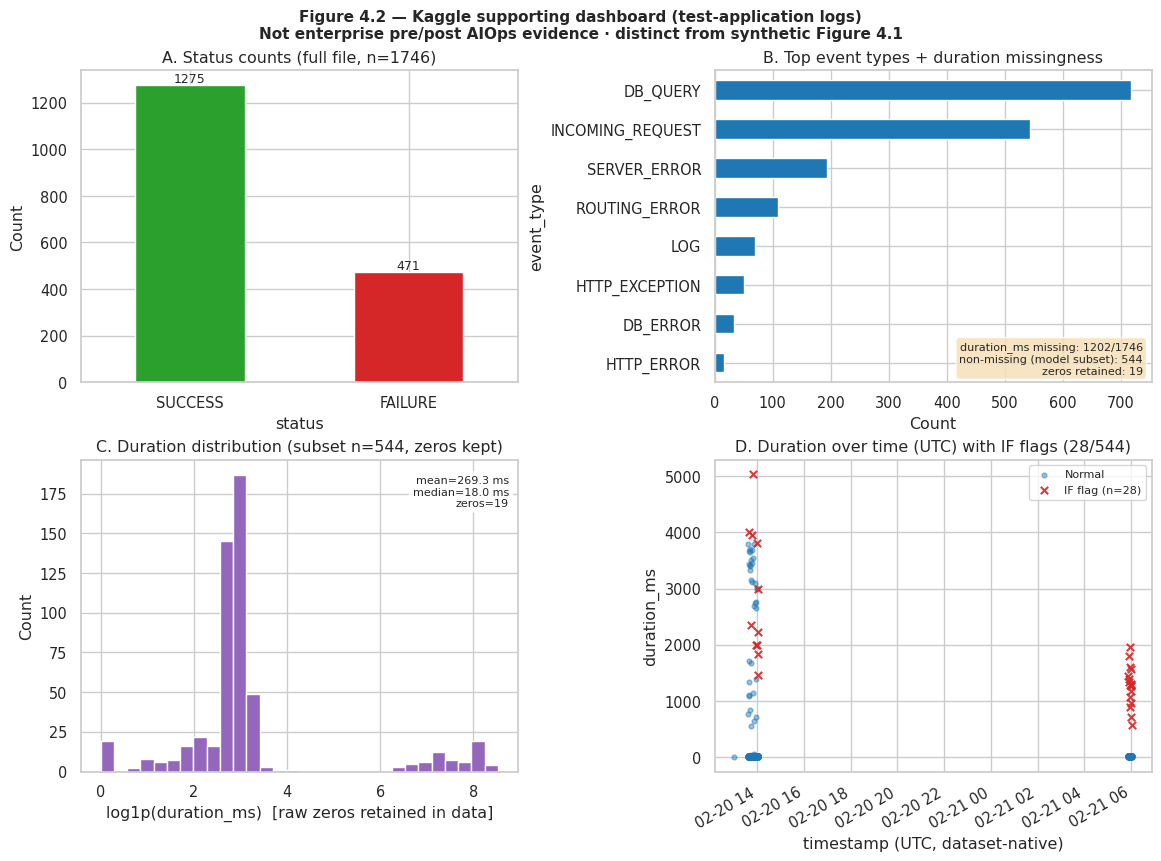

Wrote metrics /content/data/kaggle_aiops_logs/fig4_2_metrics.json


In [5]:
sns.set_theme(style='whitegrid', font_scale=0.95)
fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.5), constrained_layout=True)
fig.suptitle(
    'Figure 4.2 — Kaggle supporting dashboard (test-application logs)\n'
    'Not enterprise pre/post AIOps evidence · distinct from synthetic Figure 4.1',
    fontsize=11, fontweight='bold'
)

# A — status
ax = axes[0, 0]
status_order = df['status'].value_counts()
colors_a = ['#2ca02c' if i == 'SUCCESS' else '#d62728' if i == 'FAILURE' else '#7f7f7f' for i in status_order.index]
status_order.plot(kind='bar', ax=ax, color=colors_a, rot=0)
ax.set_title('A. Status counts (full file, n={})'.format(n))
ax.set_ylabel('Count')
for i, (lab, val) in enumerate(status_order.items()):
    ax.text(i, val, str(val), ha='center', va='bottom', fontsize=9)

# B — event types
ax = axes[0, 1]
et = df['event_type'].value_counts().head(8)
et.plot(kind='barh', ax=ax, color='#1f77b4')
ax.invert_yaxis()
ax.set_title('B. Top event types + duration missingness')
ax.set_xlabel('Count')
ax.text(0.98, 0.02,
        f'duration_ms missing: {n_miss}/{n}\n'
        f'non-missing (model subset): {n_sub}\n'
        f'zeros retained: {n_zero}',
        transform=ax.transAxes, ha='right', va='bottom', fontsize=8,
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

# C — duration distribution (subset)
ax = axes[1, 0]
durs = sub['duration_ms'].astype(float)
# log1p histogram handles zero-heavy skew without dropping zeros
ax.hist(np.log1p(durs), bins=30, color='#9467bd', edgecolor='white')
ax.set_title('C. Duration distribution (subset n={}, zeros kept)'.format(n_sub))
ax.set_xlabel('log1p(duration_ms)  [raw zeros retained in data]')
ax.set_ylabel('Count')
ax.text(0.98, 0.95,
        f'mean={durs.mean():.1f} ms\nmedian={durs.median():.1f} ms\nzeros={int((durs==0).sum())}',
        transform=ax.transAxes, ha='right', va='top', fontsize=8,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))

# D — duration over UTC with flags
ax = axes[1, 1]
plot_df = sub.dropna(subset=['timestamp_utc']).sort_values('timestamp_utc')
normal = plot_df[plot_df['anomaly_flag'] == 1]
flags = plot_df[plot_df['anomaly_flag'] == -1]
ax.scatter(normal['timestamp_utc'], normal['duration_ms'], s=12, alpha=0.45, c='#1f77b4', label='Normal')
ax.scatter(flags['timestamp_utc'], flags['duration_ms'], s=28, alpha=0.9, c='#d62728', marker='x', label=f'IF flag (n={n_flags})')
ax.set_title('D. Duration over time (UTC) with IF flags ({}/{})'.format(n_flags, n_sub))
ax.set_xlabel('timestamp (UTC, dataset-native)')
ax.set_ylabel('duration_ms')
ax.legend(loc='upper right', fontsize=8)
for label in ax.get_xticklabels():
    label.set_rotation(30)
    label.set_horizontalalignment('right')

# Output path: next to notebook or /content in Colab
out_candidates = [
    Path('figures/fig4_2_kaggle_dashboard.png'),
    Path('../figures/fig4_2_kaggle_dashboard.png'),
    Path('/content/fig4_2_kaggle_dashboard.png'),
    Path('fig4_2_kaggle_dashboard.png'),
]
OUT_PNG = out_candidates[0]
OUT_PNG.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(OUT_PNG, dpi=160, bbox_inches='tight', facecolor='white')
print('Saved', OUT_PNG.resolve(), 'bytes', OUT_PNG.stat().st_size)
plt.show()

# Persist metrics beside figures / data
metrics_paths = [
    Path('data/kaggle_aiops_logs/fig4_2_metrics.json'),
    Path('../data/kaggle_aiops_logs/fig4_2_metrics.json'),
    Path('/content/fig4_2_metrics.json'),
]
METRICS['png'] = str(OUT_PNG.resolve())
METRICS['png_sha256'] = hashlib.sha256(OUT_PNG.read_bytes()).hexdigest()
for mp in metrics_paths:
    try:
        mp.parent.mkdir(parents=True, exist_ok=True)
        mp.write_text(json.dumps(METRICS, indent=2, default=str))
        print('Wrote metrics', mp.resolve())
        break
    except Exception as e:
        print('skip', mp, e)
